---
## Unidad 22. Pila (*Stack*)

### 1. Teoría Concisa
Una **Pila (*Stack*)** es una estructura de datos lineal que sigue el principio **LIFO** (*Last In, First Out* — **Último en Entrar, Primero en Salir**).

* **Analogía cotidiana:** Imagina una pila de platos limpios o el botón **"Deshacer" (`Ctrl + Z`)** de un editor de texto. El último plato que colocas en la cima es siempre el primero que retiras; la última acción que escribiste es la primera que se deshace.
* **Operaciones principales:**
  * **`push` (Apilar):** Agrega un elemento en la cima (*tope*) de la pila $\rightarrow$ en Python se usa `pila.append(x)` con costo **$O(1)$**.
  * **`pop` (Desapilar):** Retira y devuelve el elemento de la cima $\rightarrow$ en Python se usa `pila.pop()` con costo **$O(1)$**.
  * **`peek` / `top` (Consultar cima):** Observa el elemento superior sin eliminarlo $\rightarrow$ en Python se usa `pila[-1]` con costo **$O(1)$**.
  * **`is_empty` (Verificar si está vacía):** En Python se evalúa directamente `not pila` o `len(pila) == 0`.

### 2. Ejemplo Sencillo en Python: Historial de "Deshacer" (`Ctrl + Z`)

In [ ]:
# Ejemplo práctico y sencillo de una Pila (Stack) simulando "Ctrl + Z"
historial_acciones = []

# 1. Apilar acciones (Push -> append)
historial_acciones.append("Escribir título")
historial_acciones.append("Poner texto en negrita")
historial_acciones.append("Insertar imagen")

print("Estado actual de la pila:", historial_acciones)
print("Última acción en la cima (peek):", historial_acciones[-1])

# 2. Deshacer la última acción (Pop -> pop)
accion_deshecha = historial_acciones.pop()
print(f"\nSe presionó Ctrl+Z -> Acción deshecha: '{accion_deshecha}'")
print("Pila después de deshacer:", historial_acciones)

Estado actual de la pila: ['Escribir título', 'Poner texto en negrita', 'Insertar imagen']
Última acción en la cima (peek): Insertar imagen

Se presionó Ctrl+Z -> Acción deshecha: 'Insertar imagen'
Pila después de deshacer: ['Escribir título', 'Poner texto en negrita']


### 3. Gráfico Ilustrativo: Funcionamiento de una Pila (LIFO)
A continuación visualizamos gráficamente cómo evoluciona una pila durante las operaciones `push` y `pop`, destacando cómo todo ocurre exclusivamente en el **tope (cima)** de la estructura.

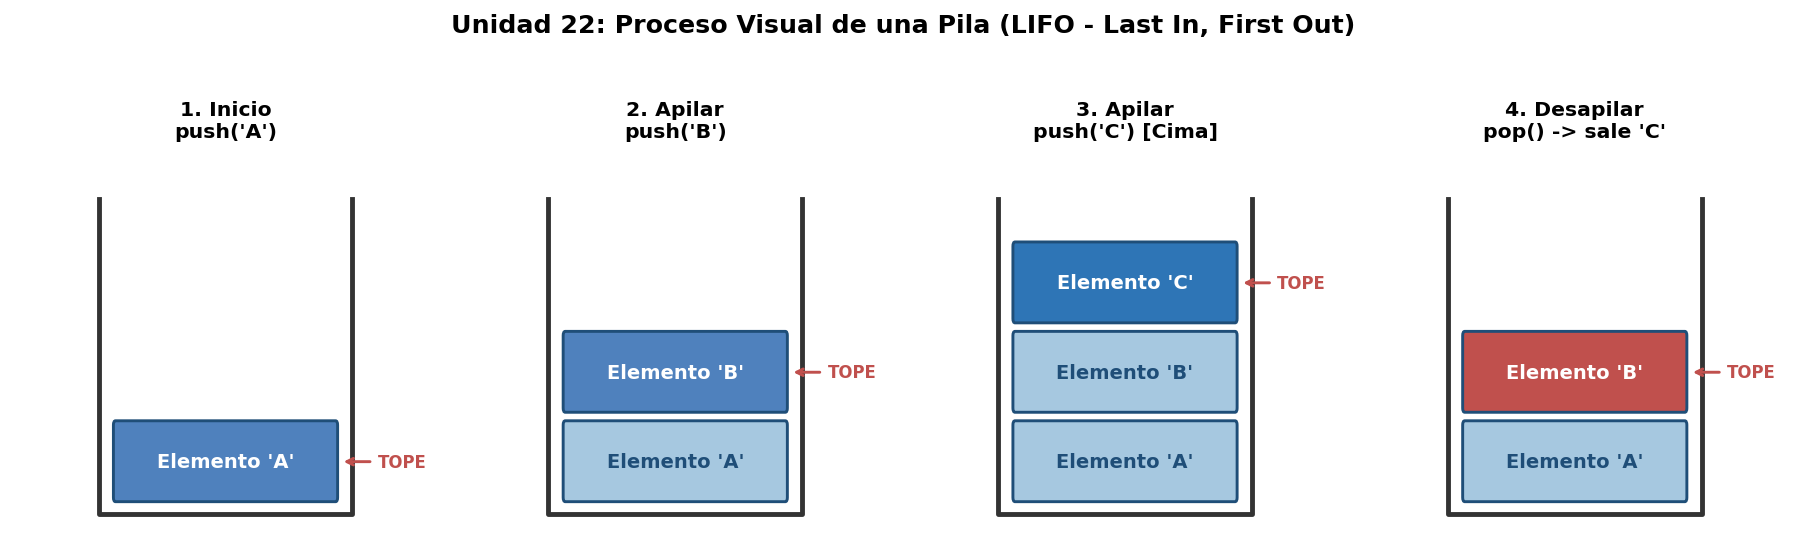

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharey=True)
fig.suptitle("Unidad 22: Proceso Visual de una Pila (LIFO - Last In, First Out)", fontsize=13, fontweight="bold", y=1.03)

estados_pila = [
    ("1. Inicio\npush('A')", ["A"], "#4F81BD"),
    ("2. Apilar\npush('B')", ["A", "B"], "#4F81BD"),
    ("3. Apilar\npush('C') [Cima]", ["A", "B", "C"], "#2E75B6"),
    ("4. Desapilar\npop() -> sale 'C'", ["A", "B"], "#C0504D")
]

for ax, (titulo, elementos, color_tope) in zip(axes, estados_pila):
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 4.5)
    ax.axis("off")
    ax.set_title(titulo, fontsize=10.5, fontweight="bold", pad=10)

    # Dibujar contenedor de la pila (U-shape)
    ax.plot([2, 2, 8, 8], [4.0, 0.3, 0.3, 4.0], color="#333333", lw=2.5)

    for idx, elem in enumerate(elementos):
        es_tope = (idx == len(elementos) - 1)
        color_caja = color_tope if es_tope else "#A6C8E0"
        rect = patches.FancyBboxPatch((2.4, 0.5 + idx * 1.05), 5.2, 0.85,
                                      boxstyle="round,pad=0.05", facecolor=color_caja, edgecolor="#1F4E78", lw=1.5)
        ax.add_patch(rect)
        ax.text(5.0, 0.92 + idx * 1.05, f"Elemento '{elem}'", ha="center", va="center",
                fontsize=10, fontweight="bold", color="white" if es_tope else "#1F4E78")
        if es_tope:
            ax.annotate("TOPE", xy=(7.7, 0.92 + idx * 1.05), xytext=(8.6, 0.92 + idx * 1.05),
                        arrowprops=dict(arrowstyle="->", color="#C0504D", lw=1.5),
                        fontsize=8.5, fontweight="bold", color="#C0504D", va="center")

plt.tight_layout()
plt.show()

---
## Unidad 23. Cola (*Queue*)

### 1. Teoría Concisa
Una **Cola (*Queue*)** es una estructura de datos lineal que sigue el principio **FIFO** (*First In, First Out* — **Primero en Entrar, Primero en Salir**).

* **Analogía cotidiana:** Una fila de clientes en un banco o la cola de documentos enviados a una impresora. El primer documento en enviarse es el primero en imprimirse.
* **Operaciones principales:**
  * **`enqueue` (Encolar):** Inserta un elemento al **final** (*rear/back*) de la cola $\rightarrow$ `cola.append(x)` con costo **$O(1)$**.
  * **`dequeue` (Desencolar):** Extrae el primer elemento del **frente** (*front*) de la cola $\rightarrow$ `cola.popleft()` usando `collections.deque` con costo **$O(1)$**.
* **Advertencia clave en Python (`list` vs `deque`):**
  Aunque puedes hacer `lista.pop(0)` en una lista normal de Python, **es una mala práctica para colas grandes**: al borrar el primer elemento de un `list`, Python debe desplazar en memoria todos los demás elementos una posición hacia la izquierda, lo que toma tiempo lineal **$O(n)$**. En cambio, `collections.deque` (*Double-Ended Queue*) está implementada como una lista doblemente enlazada de bloques y realiza `popleft()` en tiempo constante **$O(1)$**.

### 2. Ejemplo Sencillo en Python: Cola de Impresión con `collections.deque`

In [ ]:
from collections import deque

# Creamos una cola eficiente usando deque
cola_impresion = deque()

# 1. Encolar documentos (Enqueue -> append)
cola_impresion.append("Factura_001.pdf")
cola_impresion.append("Reporte_Ventas.xlsx")
cola_impresion.append("Presentacion.pptx")

print("Cola de impresión inicial:", list(cola_impresion))

# 2. Atender el primer documento en llegar (Dequeue -> popleft)
imprimiendo = cola_impresion.popleft()
print(f"\nImprimiendo ahora (primero en llegar): '{imprimiendo}'")
print("Documentos pendientes en la cola:", list(cola_impresion))

Cola de impresión inicial: ['Factura_001.pdf', 'Reporte_Ventas.xlsx', 'Presentacion.pptx']

Imprimiendo ahora (primero en llegar): 'Factura_001.pdf'
Documentos pendientes en la cola: ['Reporte_Ventas.xlsx', 'Presentacion.pptx']


### 3. Gráfico Ilustrativo: Estructura FIFO y Rendimiento `list.pop(0)` vs `deque.popleft()`
El siguiente gráfico doble muestra:
1. **Izquierda:** El flujo visual de entrada (`enqueue` por el final) y salida (`dequeue` por el frente) en una Cola FIFO.
2. **Derecha:** Una prueba real de tiempo de ejecución en Python que demuestra por qué `collections.deque` es exponencialmente superior a `list.pop(0)`.

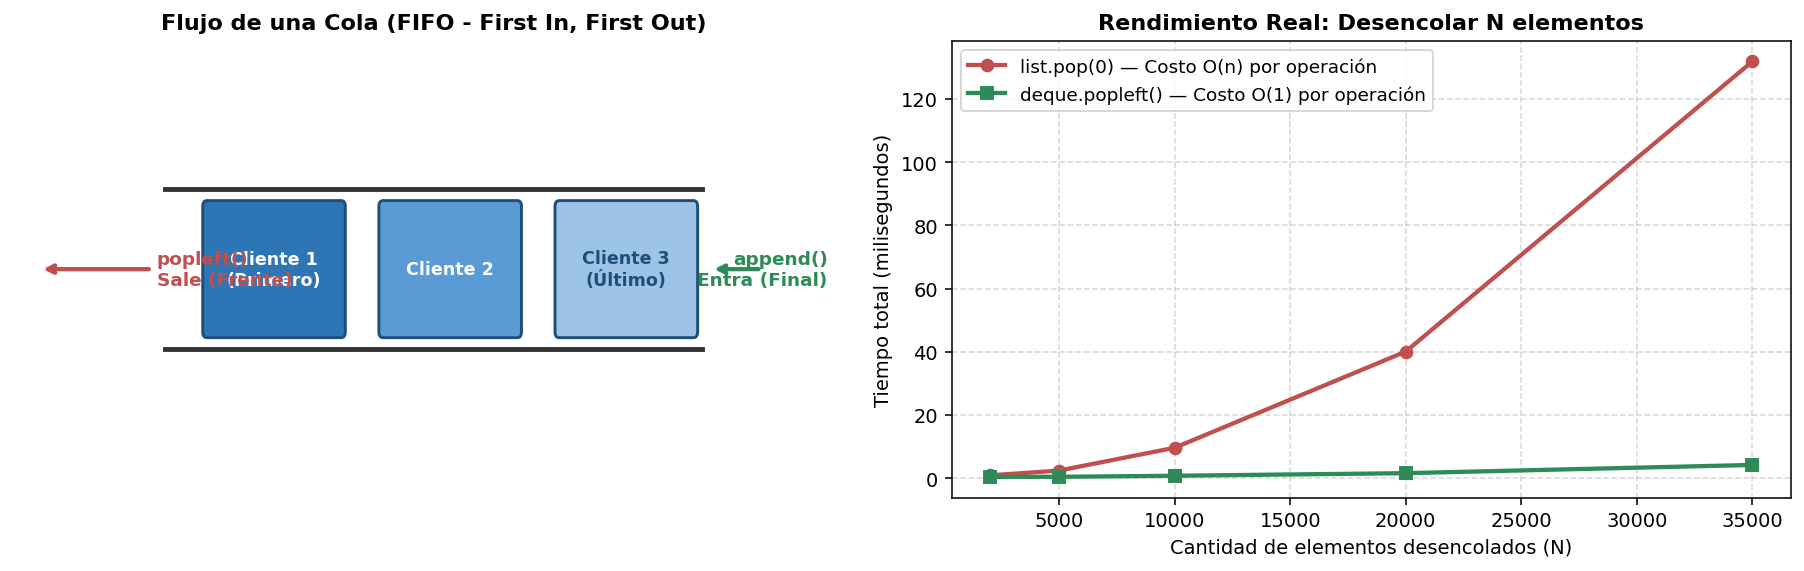

In [ ]:
import time
from collections import deque
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Medición empírica de tiempos para desencolar elementos
tamanos = [2000, 5000, 10000, 20000, 35000]
tiempos_list = []
tiempos_deque = []

for n in tamanos:
    lista_test = list(range(n))
    t0 = time.perf_counter()
    while lista_test:
        lista_test.pop(0)
    tiempos_list.append((time.perf_counter() - t0) * 1000) # ms

    deque_test = deque(range(n))
    t0 = time.perf_counter()
    while deque_test:
        deque_test.popleft()
    tiempos_deque.append((time.perf_counter() - t0) * 1000) # ms

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))

# Panel 1: Diagrama de flujo FIFO
ax1.set_xlim(0, 10)
ax1.set_ylim(0, 4)
ax1.axis("off")
ax1.set_title("Flujo de una Cola (FIFO - First In, First Out)", fontsize=11.5, fontweight="bold")

# Líneas del túnel de la cola
ax1.plot([1.8, 8.2], [2.7, 2.7], color="#333333", lw=2.5)
ax1.plot([1.8, 8.2], [1.3, 1.3], color="#333333", lw=2.5)

clientes = [("Cliente 1\n(Primero)", 2.3, "#2E75B6"), ("Cliente 2", 4.4, "#5B9BD5"), ("Cliente 3\n(Último)", 6.5, "#9DC3E6")]
for texto, x_pos, col in clientes:
    box = patches.FancyBboxPatch((x_pos, 1.45), 1.6, 1.1, boxstyle="round,pad=0.05", facecolor=col, edgecolor="#1F4E78", lw=1.5)
    ax1.add_patch(box)
    ax1.text(x_pos + 0.8, 2.0, texto, ha="center", va="center", color="white" if col != "#9DC3E6" else "#1F4E78", fontsize=9, fontweight="bold")

ax1.annotate("popleft()\nSale (Frente)", xy=(0.3, 2.0), xytext=(1.7, 2.0),
             arrowprops=dict(arrowstyle="->", color="#C0504D", lw=2.2), fontsize=9.5, fontweight="bold", color="#C0504D", va="center")
ax1.annotate("append()\nEntra (Final)", xy=(8.3, 2.0), xytext=(9.7, 2.0),
             arrowprops=dict(arrowstyle="->", color="#2E8B57", lw=2.2), fontsize=9.5, fontweight="bold", color="#2E8B57", va="center", ha="right")

# Panel 2: Benchmark real list.pop(0) vs deque.popleft()
ax2.plot(tamanos, tiempos_list, marker="o", color="#C0504D", lw=2.2, label="list.pop(0) — Costo O(n) por operación")
ax2.plot(tamanos, tiempos_deque, marker="s", color="#2E8B57", lw=2.2, label="deque.popleft() — Costo O(1) por operación")
ax2.set_title("Rendimiento Real: Desencolar N elementos", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Cantidad de elementos desencolados (N)", fontsize=10)
ax2.set_ylabel("Tiempo total (milisegundos)", fontsize=10)
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(fontsize=9.5)

plt.tight_layout()
plt.show()

---
## Unidad 24. Búsqueda Secuencial (*Linear / Sequential Search*)

### 1. Teoría Concisa
La **Búsqueda Secuencial** (o búsqueda lineal) es el algoritmo más directo para localizar un valor dentro de una colección: recorre la lista **elemento por elemento**, desde el inicio hasta encontrar el dato buscado o llegar al final.

* **¿Necesita que los datos estén ordenados?** **No.** Funciona exactamente igual en listas desordenadas u ordenadas.
* **Complejidad temporal:**
  * **Mejor caso $O(1)$:** El elemento buscado está en la primera posición (índice `0`).
  * **Caso promedio $O(n/2) \equiv O(n)$:** El elemento está hacia la mitad de la lista.
  * **Peor caso $O(n)$:** El elemento está en la última posición o no existe en la lista.
* **¿Cuándo usarla?** Cuando la lista **no está ordenada**, cuando es pequeña (ej. menos de 100 elementos) o cuando solo vas a realizar una única búsqueda (ya que ordenar la lista primero costaría $O(n \log n)$, que es más caro que un solo recorrido $O(n)$).

### 2. Ejemplo Sencillo en Python: Función Explícita y Forma Idiomática

In [ ]:
def busqueda_secuencial(lista, objetivo):
    """Recorre la lista paso a paso. Devuelve (índice, pasos_realizados)."""
    for indice, valor in enumerate(lista):
        if valor == objetivo:
            return indice, indice + 1  # Encontrado
    return -1, len(lista)              # No encontrado

productos = ["Teclado", "Mouse", "Monitor", "Laptop", "Webcam", "Micrófono"]
objetivo = "Laptop"

pos, pasos = busqueda_secuencial(productos, objetivo)
print(f"Buscando '{objetivo}' en {productos}")
print(f"-> Encontrado en el índice {pos} tras realizar {pasos} comparaciones.")

# Forma nativa e idiomática en Python:
if objetivo in productos:
    print(f"-> Con método nativo: productos.index('{objetivo}') = {productos.index(objetivo)}")

Buscando 'Laptop' en ['Teclado', 'Mouse', 'Monitor', 'Laptop', 'Webcam', 'Micrófono']
-> Encontrado en el índice 3 tras realizar 4 comparaciones.
-> Con método nativo: productos.index('Laptop') = 3


### 3. Gráfico Ilustrativo: Traza Paso a Paso de la Búsqueda Secuencial
Observemos cómo la búsqueda secuencial inspecciona casilla por casilla de izquierda a derecha hasta encontrar el número `42` en el índice `4`.

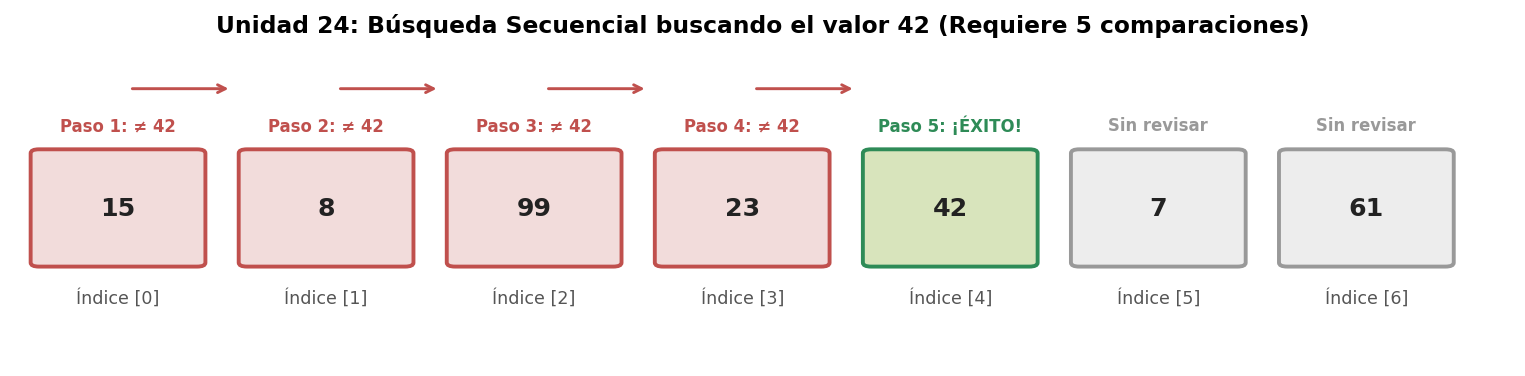

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

datos_seq = [15, 8, 99, 23, 42, 7, 61]
objetivo_seq = 42
indice_encontrado = datos_seq.index(objetivo_seq)

fig, ax = plt.subplots(figsize=(11, 2.8))
ax.set_xlim(-0.5, len(datos_seq) - 0.3)
ax.set_ylim(0, 3.2)
ax.axis("off")
ax.set_title(f"Unidad 24: Búsqueda Secuencial buscando el valor {objetivo_seq} (Requiere {indice_encontrado + 1} comparaciones)",
             fontsize=12, fontweight="bold")

for i, val in enumerate(datos_seq):
    if i < indice_encontrado:
        color_fondo = "#F2DCDB"   # Descartado tras comparar
        color_borde = "#C0504D"
        estado = f"Paso {i+1}: ≠ {objetivo_seq}"
    elif i == indice_encontrado:
        color_fondo = "#D8E4BC"   # ¡Encontrado!
        color_borde = "#2E8B57"
        estado = f"Paso {i+1}: ¡ÉXITO!"
    else:
        color_fondo = "#EDEDED"   # No fue necesario revisar
        color_borde = "#999999"
        estado = "Sin revisar"

    rect = patches.FancyBboxPatch((i - 0.38, 1.0), 0.76, 1.1, boxstyle="round,pad=0.04",
                                  facecolor=color_fondo, edgecolor=color_borde, lw=2)
    ax.add_patch(rect)
    ax.text(i, 1.55, str(val), ha="center", va="center", fontsize=13, fontweight="bold", color="#222222")
    ax.text(i, 0.65, f"Índice [{i}]", ha="center", va="center", fontsize=9, color="#555555")
    ax.text(i, 2.38, estado, ha="center", va="center", fontsize=8.5, fontweight="bold", color=color_borde)

    # Flecha entre pasos revisados
    if i < indice_encontrado:
        ax.annotate("", xy=(i + 0.55, 2.75), xytext=(i + 0.05, 2.75),
                    arrowprops=dict(arrowstyle="->", color="#C0504D", lw=1.5))

plt.tight_layout()
plt.show()

---
## Unidad 25. Búsqueda Binaria (*Binary Search*)

### 1. Teoría Concisa
La **Búsqueda Binaria** es un algoritmo sumamente rápido basado en la estrategia **Dividir y Vencer (*Divide and Conquer*)**. En lugar de revisar uno por uno, consulta el **elemento central** de la colección:
* Si el elemento central es igual al objetivo, ¡terminamos!
* Si el objetivo es **mayor** que el centro, descartamos de golpe toda la **mitad izquierda**.
* Si el objetivo es **menor** que el centro, descartamos toda la **mitad derecha**.

* **Requisito obligatorio:** La colección **DEBE estar ordenada previamente** de forma ascendente (o descendente).
* **Complejidad temporal:** **$O(\log_2 n)$**.
  * *Ejemplo del poder logarítmico:* En una lista ordenada de **1,000,000 de elementos**, la búsqueda secuencial puede tardar hasta `1,000,000` de pasos, mientras que la búsqueda binaria encuentra cualquier dato en **como máximo 20 pasos** ($\log_2(10^6) \approx 19.93$).
* **Módulo nativo en Python (`bisect`):** Python incluye en su librería estándar el módulo `bisect` (implementado en C para máxima velocidad), que ejecuta búsqueda binaria mediante `bisect.bisect_left(lista, x)` e inserción ordenada con `bisect.insort(lista, x)`.

### 2. Ejemplo Sencillo en Python: Implementación Paso a Paso y Uso de `bisect`

In [ ]:
import bisect

def busqueda_binaria_traza(lista_ordenada, objetivo):
    """Búsqueda binaria guardando cada recorte de [izquierda, centro, derecha]."""
    izq = 0
    der = len(lista_ordenada) - 1
    pasos = []

    while izq <= der:
        centro = (izq + der) // 2
        valor_medio = lista_ordenada[centro]
        pasos.append((izq, centro, der, valor_medio))

        if valor_medio == objetivo:
            return centro, pasos
        elif valor_medio < objetivo:
            izq = centro + 1  # Descartar mitad izquierda
        else:
            der = centro - 1  # Descartar mitad derecha

    return -1, pasos

precios_ordenados = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110]
objetivo_bin = 80

indice_res, historial_pasos = busqueda_binaria_traza(precios_ordenados, objetivo_bin)
print(f"Lista ordenada: {precios_ordenados}")
for num_paso, (i, c, d, val) in enumerate(historial_pasos, 1):
    print(f"  Paso {num_paso}: Rango [{i}..{d}] -> Centro en índice [{c}] (valor={val})")
print(f"-> ¡Encontrado el valor {objetivo_bin} en el índice {indice_res} en solo {len(historial_pasos)} pasos!")

# Uso profesional con la librería estándar bisect:
pos_bisect = bisect.bisect_left(precios_ordenados, objetivo_bin)
print(f"-> Verificación con bisect.bisect_left: índice {pos_bisect}")

Lista ordenada: [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110]
  Paso 1: Rango [0..10] -> Centro en índice [5] (valor=60)
  Paso 2: Rango [6..10] -> Centro en índice [8] (valor=90)
  Paso 3: Rango [6..7] -> Centro en índice [6] (valor=70)
  Paso 4: Rango [7..7] -> Centro en índice [7] (valor=80)
-> ¡Encontrado el valor 80 en el índice 7 en solo 4 pasos!
-> Verificación con bisect.bisect_left: índice 7


### 3. Gráfico Ilustrativo: Cómo la Búsqueda Binaria Divide el Espacio a la Mitad
En la siguiente figura vemos cada iteración del ejemplo anterior buscando el número `80`: en cada fila las celdas grises quedan descartadas de golpe, el recuadro naranja señala el `centro` evaluado y el verde marca el hallazgo final.

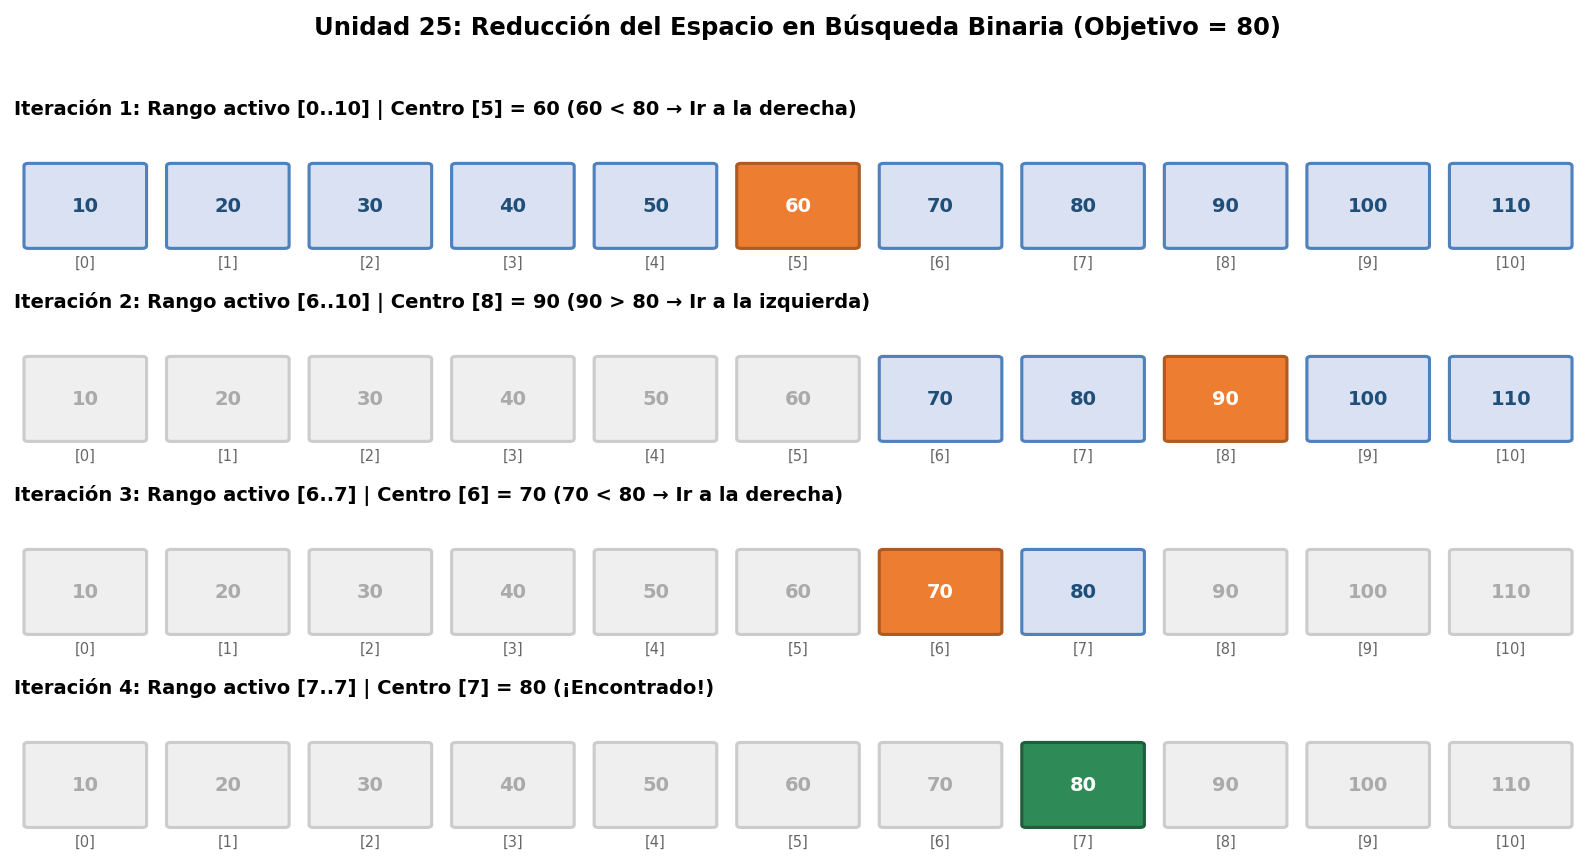

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

n_elem = len(precios_ordenados)
num_iter = len(historial_pasos)

fig, axes = plt.subplots(num_iter, 1, figsize=(11.5, 1.5 * num_iter))
if num_iter == 1:
    axes = [axes]

fig.suptitle(f"Unidad 25: Reducción del Espacio en Búsqueda Binaria (Objetivo = {objetivo_bin})",
             fontsize=12.5, fontweight="bold", y=1.02)

for idx_paso, (ax, (izq, centro, der, val_medio)) in enumerate(zip(axes, historial_pasos), 1):
    ax.set_xlim(-0.5, n_elem - 0.5)
    ax.set_ylim(0, 1.6)
    ax.axis("off")

    accion = "¡Encontrado!" if val_medio == objetivo_bin else (
        f"{val_medio} < {objetivo_bin} → Ir a la derecha" if val_medio < objetivo_bin else f"{val_medio} > {objetivo_bin} → Ir a la izquierda"
    )
    ax.set_title(f"Iteración {idx_paso}: Rango activo [{izq}..{der}] | Centro [{centro}] = {val_medio} ({accion})",
                 fontsize=10, fontweight="bold", loc="left")

    for i, valor in enumerate(precios_ordenados):
        if i < izq or i > der:
            bg, fg, border = "#EFEFEF", "#AAAAAA", "#CCCCCC"  # Descartado
        elif i == centro:
            if valor == objetivo_bin:
                bg, fg, border = "#2E8B57", "white", "#1E5E3A"  # Encontrado
            else:
                bg, fg, border = "#ED7D31", "white", "#AE5A21"  # Centro actual
        else:
            bg, fg, border = "#D9E1F2", "#1F4E78", "#4F81BD"  # Rango activo

        rect = patches.FancyBboxPatch((i - 0.4, 0.25), 0.8, 0.9, boxstyle="round,pad=0.03",
                                      facecolor=bg, edgecolor=border, lw=1.6)
        ax.add_patch(rect)
        ax.text(i, 0.7, str(valor), ha="center", va="center", fontsize=10, fontweight="bold", color=fg)
        ax.text(i, 0.05, f"[{i}]", ha="center", va="center", fontsize=7.5, color="#666666")

plt.tight_layout()
plt.show()

---
## Unidad 26. Tabla Hash (*Hash Table*)

### 1. Teoría Concisa
Una **Tabla Hash (*Hash Table*)** es una estructura de datos que almacena pares **Clave $\rightarrow$ Valor** (*Key-Value*) y permite buscar, insertar o eliminar datos en tiempo prácticamente instantáneo: **$O(1)$ en promedio**.

* **¿Cómo funciona por dentro?**
  1. **Función Hash (`hash(clave)`):** Convierte cualquier clave inmutable (por ejemplo, el texto `"Ana"`) en un número entero único.
  2. **Cálculo de índice (Cubeta / *Bucket*):** Aplica el operador módulo sobre el tamaño de la tabla (`indice = hash(clave) % capacidad`) para saber exactamente en qué casilla de memoria guardar o buscar el dato, **sin recorrer el resto de elementos**.
  3. **Colisiones (*Collisions*):** Ocurren cuando dos claves distintas producen el mismo índice (`hash(k1) % M == hash(k2) % M`). Se resuelven principalmente de dos formas:
     * **Encadenamiento separado (*Chaining*):** Cada casilla guarda una pequeña lista con los elementos que colisionaron.
     * **Direccionamiento abierto (*Open Addressing*):** Utilizado por Python en `dict` y `set`, donde si una casilla está ocupada, se calcula otra casilla libre siguiendo una secuencia matemática de sondeo (*probing*).
* **Implementación nativa en Python:** Los diccionarios (`dict`) y conjuntos (`set`) son tablas hash altamente optimizadas. Desde **Python 3.6 / 3.7+**, los diccionarios usan un **diseño compacto (*Compact Dict*)** que reduce el consumo de memoria entre un 20% y 25% y **preserva por garantía del lenguaje el orden de inserción**.

### 2. Ejemplo Sencillo en Python: Diccionario Nativo y Cómo Funciona una Tabla Hash por Dentro

In [ ]:
# 1. Uso cotidiano en Python: dict (Tabla Hash nativa)
agenda_telefonos = {
    "Ana": "+58-412-1112233",
    "Luis": "+58-414-9998877",
    "Marta": "+58-424-5554433"
}

# Búsqueda instantánea O(1) por clave:
print("Teléfono de Luis (O(1)):", agenda_telefonos["Luis"])

# 2. Mini Tabla Hash educativa (con manejo de colisiones por encadenamiento)
class MiniTablaHash:
    def __init__(self, capacidad=5):
        self.capacidad = capacidad
        self.cubetas = [[] for _ in range(capacidad)]

    def _indice_hash(self, clave):
        # Suma simple de códigos ASCII módulo capacidad para que sea fácil de ver
        return sum(ord(c) for c in str(clave)) % self.capacidad

    def guardar(self, clave, valor):
        idx = self._indice_hash(clave)
        for i, (k, v) in enumerate(self.cubetas[idx]):
            if k == clave:
                self.cubetas[idx][i] = (clave, valor)
                return idx
        self.cubetas[idx].append((clave, valor))
        return idx

tabla_demo = MiniTablaHash(capacidad=5)
for nombre, nota in [("Ana", 19), ("Luis", 18), ("Marta", 20), ("Leo", 17), ("Eva", 20)]:
    cubeta = tabla_demo.guardar(nombre, nota)
    print(f"Clave '{nombre}' -> Función Hash asignó Cubeta [{cubeta}]")

print("\nEstado interno de las cubetas (nota cómo se resuelven colisiones en la misma lista):")
for idx, contenido in enumerate(tabla_demo.cubetas):
    print(f"  Cubeta [{idx}]: {contenido}")

Teléfono de Luis (O(1)): +58-414-9998877
Clave 'Ana' -> Función Hash asignó Cubeta [2]
Clave 'Luis' -> Función Hash asignó Cubeta [3]
Clave 'Marta' -> Función Hash asignó Cubeta [1]
Clave 'Leo' -> Función Hash asignó Cubeta [3]
Clave 'Eva' -> Función Hash asignó Cubeta [4]

Estado interno de las cubetas (nota cómo se resuelven colisiones en la misma lista):
  Cubeta [0]: []
  Cubeta [1]: [('Marta', 20)]
  Cubeta [2]: [('Ana', 19)]
  Cubeta [3]: [('Luis', 18), ('Leo', 17)]
  Cubeta [4]: [('Eva', 20)]


### 3. Gráfico Ilustrativo: Mapeo de Claves mediante Función Hash y Colisiones
El siguiente diagrama muestra visualmente cómo cada clave pasa por la función hash `h(clave) % 5` y aterriza directamente en su cubeta (*bucket*), incluyendo un caso de colisión resuelta sin perder datos.

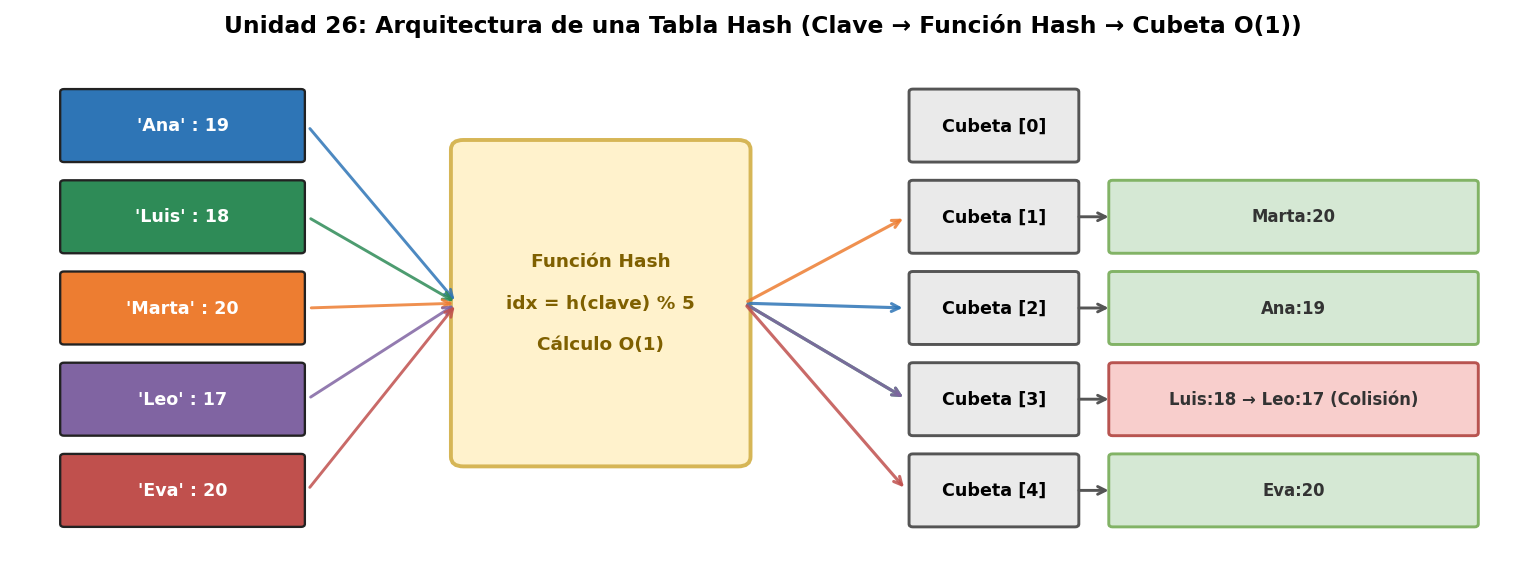

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(11, 4.3))
ax.set_xlim(0, 12)
ax.set_ylim(0, 5.5)
ax.axis("off")
ax.set_title("Unidad 26: Arquitectura de una Tabla Hash (Clave → Función Hash → Cubeta O(1))",
             fontsize=12, fontweight="bold")

claves_ejemplo = [("Ana", 19), ("Luis", 18), ("Marta", 20), ("Leo", 17), ("Eva", 20)]
colores_claves = ["#2E75B6", "#2E8B57", "#ED7D31", "#8064A2", "#C0504D"]

# Caja central: Función Hash
hash_box = patches.FancyBboxPatch((3.6, 1.2), 2.2, 3.2, boxstyle="round,pad=0.1",
                                  facecolor="#FFF2CC", edgecolor="#D6B656", lw=2)
ax.add_patch(hash_box)
ax.text(4.7, 2.8, "Función Hash\n\nidx = h(clave) % 5\n\nCálculo O(1)",
        ha="center", va="center", fontsize=9.5, fontweight="bold", color="#7F6000")

# Dibujar cubetas (0 a 4) a la derecha
for b_idx in range(5):
    y_b = 4.3 - b_idx * 0.95
    b_rect = patches.FancyBboxPatch((7.2, y_b), 1.3, 0.7, boxstyle="round,pad=0.03",
                                    facecolor="#EAEAEA", edgecolor="#555555", lw=1.5)
    ax.add_patch(b_rect)
    ax.text(7.85, y_b + 0.35, f"Cubeta [{b_idx}]", ha="center", va="center", fontsize=9, fontweight="bold")

    # Mostrar elementos alojados en esta cubeta
    alojados = tabla_demo.cubetas[b_idx]
    if alojados:
        texto_alojados = " → ".join([f"{k}:{v}" for k, v in alojados])
        es_colision = len(alojados) > 1
        c_box = patches.FancyBboxPatch((8.8, y_b), 2.9, 0.7, boxstyle="round,pad=0.03",
                                       facecolor="#F8CECC" if es_colision else "#D5E8D4",
                                       edgecolor="#B85450" if es_colision else "#82B366", lw=1.5)
        ax.add_patch(c_box)
        etiqueta_extra = " (Colisión)" if es_colision else ""
        ax.text(10.25, y_b + 0.35, texto_alojados + etiqueta_extra,
                ha="center", va="center", fontsize=8.5, fontweight="bold", color="#333333")
        ax.annotate("", xy=(8.8, y_b + 0.35), xytext=(8.5, y_b + 0.35),
                    arrowprops=dict(arrowstyle="->", color="#555555", lw=1.5))

# Dibujar claves a la izquierda y sus flechas
for idx_k, ((k, v), col) in enumerate(zip(claves_ejemplo, colores_claves)):
    y_k = 4.3 - idx_k * 0.95
    k_rect = patches.FancyBboxPatch((0.4, y_k), 1.9, 0.7, boxstyle="round,pad=0.03",
                                    facecolor=col, edgecolor="#222222", lw=1.2)
    ax.add_patch(k_rect)
    ax.text(1.35, y_k + 0.35, f"'{k}' : {v}", ha="center", va="center", fontsize=9, fontweight="bold", color="white")

    # Flecha hacia Función Hash
    ax.annotate("", xy=(3.55, 2.8), xytext=(2.35, y_k + 0.35),
                arrowprops=dict(arrowstyle="->", color=col, lw=1.5, alpha=0.85))

    # Flecha desde Función Hash hacia su Cubeta destino
    b_dest = tabla_demo._indice_hash(k)
    y_dest = 4.3 - b_dest * 0.95 + 0.35
    ax.annotate("", xy=(7.15, y_dest), xytext=(5.85, 2.8),
                arrowprops=dict(arrowstyle="->", color=col, lw=1.6, alpha=0.85))

plt.tight_layout()
plt.show()

---
## Actualizaciones de Python en las Últimas Versiones (Python 3.9 – 3.15)

Python ha evolucionado notablemente tanto en la sintaxis como en el rendimiento interno de sus estructuras de datos y algoritmos de búsqueda. A continuación se resumen las mejoras oficiales más importantes relacionadas con estos 5 temas:

| Versión | Tema Relacionado | Actualización / Mejora Oficial | Impacto Práctico |
| :--- | :--- | :--- | :--- |
| **Python 3.9** ([PEP 584](https://docs.python.org/3/whatsnew/3.9.html)) | **Tabla Hash (`dict`) y Tipado Genérico ([PEP 585](https://docs.python.org/3/whatsnew/3.9.html))** | Nuevos operadores de unión de diccionarios `d1 \| d2` y actualización `d1 \|= d2`. Además, ahora se puede anotar `list[int]`, `dict[str, int]` y `deque[str]` directamente sin importar `typing.List` o `typing.Dict`. | Fusión de tablas hash mucho más legible y limpia. |
| **Python 3.10** ([What's New 3.10](https://docs.python.org/3/whatsnew/3.10.html)) | **Búsqueda Binaria (`bisect`) y `dict`** | Se añadió el parámetro **`key=`** a todas las funciones de [`bisect`](https://docs.python.org/3/library/bisect.html) (`bisect_left`, `bisect_right`, `insort_left`, `insort_right`). Además, `dict.keys()`, `dict.values()` y `dict.items()` incorporaron el atributo `.mapping`. | Permite hacer búsqueda binaria directamente sobre listas de diccionarios u objetos complejos sin extraer claves aparte. |
| **Python 3.11** ([What's New 3.11](https://docs.python.org/3/whatsnew/3.11.html)) | **Tabla Hash (`dict`) y `collections.deque`** | Proyecto *Faster CPython* (**[PEP 659](https://docs.python.org/3/whatsnew/3.11.html)**): intérprete adaptativo con especialización de bytecode para accesos a `dict`/`list`, y claves Unicode compartidas en diccionarios de instancias (ahorro de memoria). `deque` mejora el copiado/serialización de subclases con `__slots__`. | Mejora de velocidad general del **10% al 60%** en búsquedas y llamadas a funciones. |
| **Python 3.12** ([What's New 3.12](https://docs.python.org/3/whatsnew/3.12.html)) | **Listas, Conjuntos y Tablas Hash** | **Comprehension Inlining ([PEP 709](https://docs.python.org/3/whatsnew/3.12.html))**: las comprensiones de listas `[...]`, diccionarios `{k: v ...}` y conjuntos `{...}` ya no crean una función oculta en la pila de llamadas; ahora se ejecutan *inline*. También se introdujo la nueva sintaxis de tipos genéricos `class Pila[T]:` (**PEP 695**). | Construir o filtrar listas y tablas hash mediante comprensiones es hasta **2 veces más rápido**. |
| **Python 3.13** ([What's New 3.13](https://docs.python.org/3/whatsnew/3.13.html)) | **Colas (`queue.Queue` / `asyncio.Queue`)** | Nuevos métodos **`Queue.shutdown()`** y excepción `QueueShutDown` tanto en `queue` como en `asyncio.Queue` para cerrar colas de trabajo de forma limpia sin usar valores centinela manuales (`None`). Además, soporte experimental *Free-Threaded* sin GIL (**PEP 703**). | Gestión segura de colas productor-consumidor en aplicaciones concurrentes. |
| **Python 3.14 y 3.15** ([What's New 3.14](https://docs.python.org/3/whatsnew/3.14.html) / [3.15](https://docs.python.org/3/whatsnew/3.15.html)) | **Colas de Prioridad (`heapq`) y Tablas Hash Inmutables** | Funciones nativas para *max-heaps* en `heapq` (3.14) e incorporación del tipo integrado **`frozendict`** y desempaquetado en comprensiones (3.15). | Tablas hash inmutables (`frozendict`) que pueden usarse a su vez como claves dentro de otro `dict` o `set`. |

### Ejemplos Sencillos de las Nuevas Características de Python (3.9+)

In [ ]:
import bisect

# 1. Python 3.9+: Operador de unión '|' y '|=' en Tablas Hash (dict)
config_base = {"host": "localhost", "puerto": 5432, "timeout": 30}
config_produccion = {"host": "db.servidor.com", "ssl": True}

# Combinamos ambos diccionarios en una sola línea limpia:
config_final = config_base | config_produccion
print("1. Fusión de diccionarios con '|' (Python 3.9+):")
print("  ", config_final)

# 2. Python 3.10+: Búsqueda binaria sobre objetos/diccionarios usando el parámetro 'key='
estudiantes_ordenados = [
    {"nombre": "Carlos", "promedio": 14.5},
    {"nombre": "Elena",  "promedio": 16.2},
    {"nombre": "Lucía",  "promedio": 18.0},
    {"nombre": "Mateo",  "promedio": 19.5},
]

# Buscamos en O(log n) al estudiante con promedio 18.0 sin crear listas auxiliares:
idx = bisect.bisect_left(estudiantes_ordenados, 18.0, key=lambda est: est["promedio"])
print("\n2. Búsqueda binaria con parámetro 'key=' en bisect (Python 3.10+):")
print(f"   Índice encontrado: {idx} -> {estudiantes_ordenados[idx]}")

# 3. Python 3.9+ / 3.10+: Tipado nativo en colecciones (PEP 585) y atributo .mapping en vistas de dict
from collections import deque

cola_tipada: deque[str] = deque(["Tarea_A", "Tarea_B"])
claves_vista = config_final.keys()
print("\n3. Atributo .mapping en vistas de diccionarios (Python 3.10+) y tipado PEP 585:")
print("   Acceso al diccionario original desde keys().mapping:", claves_vista.mapping["host"])
print("   Cola tipada deque[str]:", list(cola_tipada))

1. Fusión de diccionarios con '|' (Python 3.9+):
   {'host': 'db.servidor.com', 'puerto': 5432, 'timeout': 30, 'ssl': True}

2. Búsqueda binaria con parámetro 'key=' en bisect (Python 3.10+):
   Índice encontrado: 2 -> {'nombre': 'Lucía', 'promedio': 18.0}

3. Atributo .mapping en vistas de diccionarios (Python 3.10+) y tipado PEP 585:
   Acceso al diccionario original desde keys().mapping: db.servidor.com
   Cola tipada deque[str]: ['Tarea_A', 'Tarea_B']


---
## Apartado de Uso Actual y Buenas Prácticas en el Mundo Real

### 1. ¿Qué Estructura o Algoritmo Elegir en Cada Caso? (Tabla de Decisión)

| Necesidad en tu Proyecto | Elección Recomendada en Python | Complejidad | ¿Por qué es la mejor práctica? |
| :--- | :--- | :--- | :--- |
| **Pila (LIFO)** en un solo hilo (deshacer acciones, DFS, parseo de expresiones) | `list` (`append()` y `pop()`) | **$O(1)$** amortizado | Es rápida, compacta en memoria y aprovecha la caché del procesador. |
| **Cola (FIFO)** de propósito general (BFS, buffers de tareas, ventanas deslizantes) | `collections.deque` (`append()` y `popleft()`) | **$O(1)$** exacto | Evita el costoso desplazamiento en memoria $O(n)$ que sufre `list.pop(0)`. |
| **Cola con límite de memoria** (guardar solo los últimos $N$ eventos o logs) | `collections.deque(maxlen=N)` | **$O(1)$** | Descarta automáticamente el elemento más antiguo al llenarse, sin escribir `if len(d) > N`. |
| **Cola entre múltiples hilos o tareas asíncronas** | `queue.Queue` o `asyncio.Queue` | **$O(1)$** seguro | Incluye bloqueo seguro (*thread-safe*) y cierre limpio con `.shutdown()` (Python 3.13+). |
| **Buscar un elemento 1 sola vez** en una lista pequeña o desordenada | Operador `x in lista` / `next(...)` | **$O(n)$** | No vale la pena ordenar la lista ($O(n \log n)$) si solo vas a buscar una vez. |
| **Buscar por rangos** (ej. *"notas entre 15 y 18"*, *"precio más cercano"*) en datos ordenados | `bisect.bisect_left` / `bisect_right` | **$O(\log n)$** | Las tablas hash no sirven para buscar rangos (`>=` o `<=`); `bisect` lo resuelve al instante. |
| **Buscar miles de veces valores exactos** o eliminar duplicados | `dict` o `set` (Tabla Hash) | **$O(1)$** promedio | Convertir una lista a `set` o `dict` transforma búsquedas lentas $O(n)$ en instantáneas $O(1)$. |

### 2. Reglas de Oro y Buenas Prácticas en Python
1. **Nunca uses `list.pop(0)` ni `list.insert(0, x)` dentro de un bucle:** Si necesitas quitar o agregar elementos por el principio de la colección, usa siempre `collections.deque`.
2. **Verifica antes de hacer `pop()`:** Llamar `.pop()` sobre una pila o cola vacía lanza `IndexError`. Usa el patrón pythonico `if pila: elemento = pila.pop()`.
3. **No reinventes la búsqueda binaria en código de producción:** Es muy fácil cometer errores de borde (*off-by-one*). Usa siempre el módulo estándar `bisect`, que está escrito en C y soporta el parámetro `key=` desde Python 3.10.
4. **Si haces búsquedas repetidas con `in`, convierte tu `list` en `set`:** Hacer `if usuario in lista_usuarios:` dentro de un ciclo de $10,000$ elementos convierte tu programa en cuadrático **$O(n^2)$**. Si haces `usuarios_set = set(lista_usuarios)` antes del ciclo, el tiempo total baja a **$O(n)$**.
5. **Usa `.get(clave, valor_por_defecto)` o `collections.defaultdict` en Tablas Hash:** Evita errores `KeyError` y hace tu código mucho más limpio que llenar el programa de bloques `if clave in diccionario:`.

### 3. Ejemplo Práctico de Buenas Prácticas + Comparativa Gráfica de los 3 Métodos de Búsqueda

Buena práctica 1 — deque(maxlen=3) conserva solo los 3 más recientes: ['Error 401', 'Error 404', 'Error 500']
Buena práctica 2 — Conteo limpio en Tabla Hash con .get(): {'manzana': 3, 'pera': 2, 'uva': 1}


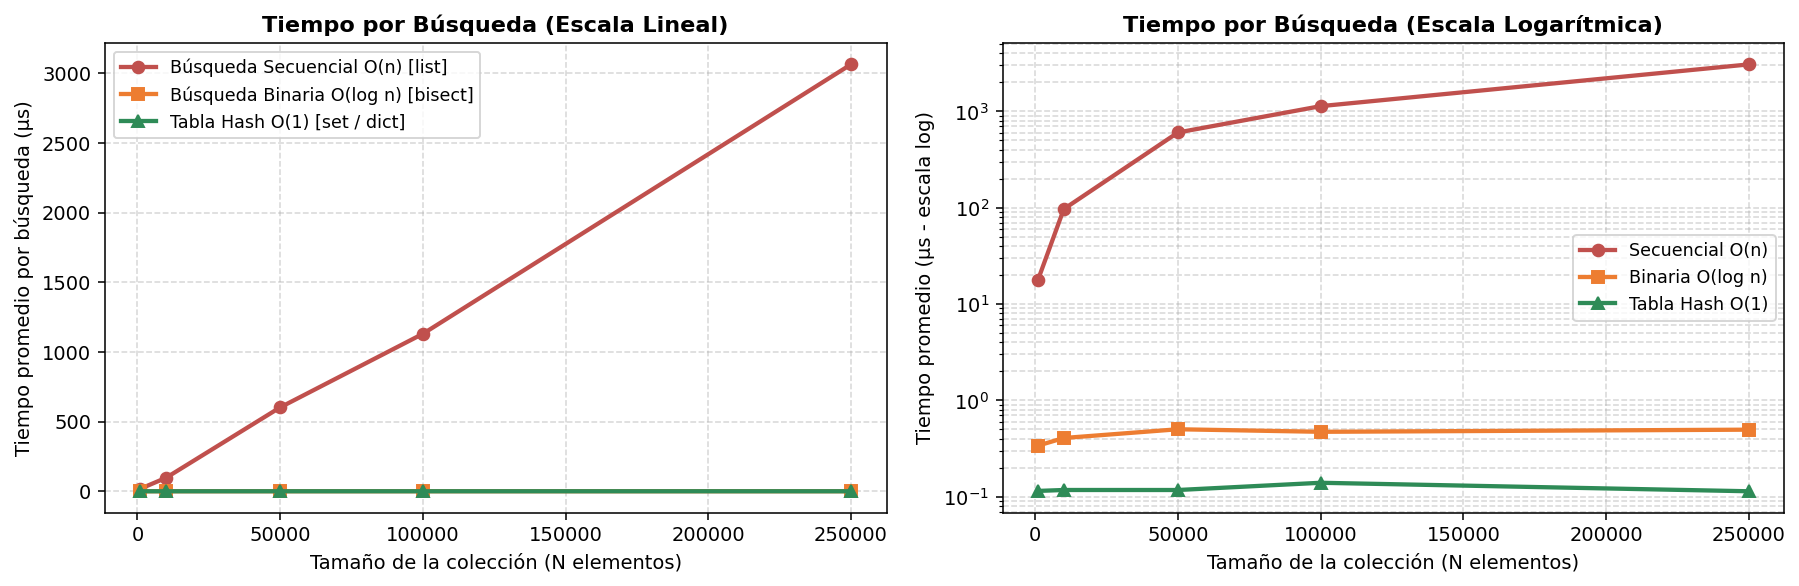

In [ ]:
import time
import bisect
import matplotlib.pyplot as plt
import numpy as np

# Demostración de buenas prácticas:
# A) Ventana deslizante automática con deque(maxlen=3)
from collections import deque
ultimos_errores = deque(maxlen=3)
for err in ["Error 400", "Error 401", "Error 404", "Error 500"]:
    ultimos_errores.append(err)
print("Buena práctica 1 — deque(maxlen=3) conserva solo los 3 más recientes:", list(ultimos_errores))

# B) Uso de dict.get() para conteo seguro en Tabla Hash
ventas = ["manzana", "pera", "manzana", "uva", "manzana", "pera"]
conteo = {}
for fruta in ventas:
    conteo[fruta] = conteo.get(fruta, 0) + 1
print("Buena práctica 2 — Conteo limpio en Tabla Hash con .get():", conteo)

# C) Comparativa visual y empírica: Búsqueda Secuencial O(n) vs Binaria O(log n) vs Tabla Hash O(1)
tamanos_busqueda = [1_000, 10_000, 50_000, 100_000, 250_000]
t_secuencial, t_binaria, t_hash = [], [], []
repeticiones = 300

for n in tamanos_busqueda:
    datos_lista = list(range(n))
    datos_set = set(datos_lista)
    objetivo_peor_caso = n - 1  # Último elemento para medir el recorrido real

    # 1. Búsqueda Secuencial (x in list)
    t0 = time.perf_counter()
    for _ in range(repeticiones):
        _ = (objetivo_peor_caso in datos_lista)
    t_secuencial.append((time.perf_counter() - t0) / repeticiones * 1e6)  # microsegundos

    # 2. Búsqueda Binaria (bisect_left)
    t0 = time.perf_counter()
    for _ in range(repeticiones):
        idx = bisect.bisect_left(datos_lista, objetivo_peor_caso)
    t_binaria.append((time.perf_counter() - t0) / repeticiones * 1e6)    # microsegundos

    # 3. Tabla Hash (x in set)
    t0 = time.perf_counter()
    for _ in range(repeticiones):
        _ = (objetivo_peor_caso in datos_set)
    t_hash.append((time.perf_counter() - t0) / repeticiones * 1e6)       # microsegundos

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))

# Gráfico 1: Escala lineal (Muestra cómo se dispara la búsqueda secuencial)
ax1.plot(tamanos_busqueda, t_secuencial, "o-", color="#C0504D", lw=2.2, label="Búsqueda Secuencial O(n) [list]")
ax1.plot(tamanos_busqueda, t_binaria, "s-", color="#ED7D31", lw=2.2, label="Búsqueda Binaria O(log n) [bisect]")
ax1.plot(tamanos_busqueda, t_hash, "^-", color="#2E8B57", lw=2.2, label="Tabla Hash O(1) [set / dict]")
ax1.set_title("Tiempo por Búsqueda (Escala Lineal)", fontsize=11.5, fontweight="bold")
ax1.set_xlabel("Tamaño de la colección (N elementos)", fontsize=10)
ax1.set_ylabel("Tiempo promedio por búsqueda (µs)", fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(fontsize=9)

# Gráfico 2: Escala logarítmica (Para apreciar la diferencia entre O(log n) y O(1))
ax2.plot(tamanos_busqueda, t_secuencial, "o-", color="#C0504D", lw=2.2, label="Secuencial O(n)")
ax2.plot(tamanos_busqueda, t_binaria, "s-", color="#ED7D31", lw=2.2, label="Binaria O(log n)")
ax2.plot(tamanos_busqueda, t_hash, "^-", color="#2E8B57", lw=2.2, label="Tabla Hash O(1)")
ax2.set_yscale("log")
ax2.set_title("Tiempo por Búsqueda (Escala Logarítmica)", fontsize=11.5, fontweight="bold")
ax2.set_xlabel("Tamaño de la colección (N elementos)", fontsize=10)
ax2.set_ylabel("Tiempo promedio (µs - escala log)", fontsize=10)
ax2.grid(True, which="both", linestyle="--", alpha=0.5)
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()